# Project: beta of the S Fund (CAPM regression)

Linear Regression track, final review project. Theory and tools: [01_the_model.ipynb](01_the_model.ipynb).

## Task

**Codecademy review:** run a linear regression on a dataset of your own choice.

Codecademy's starter regressed Boston house prices on nitrogen oxide levels (`load_boston`, `X = df[['NOX']]`): $m \approx -33.9$, $b \approx 41.3$. `load_boston` was **removed in scikit-learn 1.2**, so it only runs on Codecademy's old version. These notes use a finance dataset instead.

## Question and model

**Question:** how strongly do US small caps move with the market?

**Model (CAPM, single-index):** regress the fund's return on the market's return:

$$R_{S,t} = \alpha + \beta\, R_{M,t} + \varepsilon_t$$

- $\beta$ (slope) = market sensitivity: the market moves 1% → the fund moves $\beta$% on average. $\beta > 1$ means more market risk than the index.
- $\alpha$ (intercept) = return not explained by the market
- Use **returns, not prices**: prices both trend upward over time and would correlate almost by default

## Data and steps

**Data:** `tsp_data.csv`, US Thrift Savings Plan fund prices, 2019-01-02 to 2019-09-04 → 169 daily returns.
- Market $R_M$: **C Fund** (tracks the S&P 500)
- Fund $R_S$: **S Fund** (US small and mid caps)

**Steps:**
1. Load: the file is tab-separated, and the first column (dates) has no header → `sep='\t'`, `index_col=0`, `parse_dates=True`
2. Daily returns: `.pct_change()`, then `.dropna()` to remove the empty first row
3. X = C Fund as a one-column DataFrame (`[['C Fund']]`, 2D), y = S Fund (`['S Fund']`, 1D)
4. `LinearRegression().fit(X, y)` → $\beta$ = `coef_[0]`, $\alpha$ = `intercept_`
5. Scatter of daily returns plus the fitted line

## Results

| | value | meaning |
|---|---|---|
| $\beta$ | 1.09 | small caps amplify market moves by about 9% |
| $\alpha$ | −0.0002 per day | ≈ −0.02%/day, roughly −5% a year: small caps lagged large caps in 2019 |
| $R^2$ | 0.87 | the market explains most of the S Fund's daily moves |

**Caveats:** sklearn gives no standard errors or p-values (unlike R's `summary(lm(...))`), so $\alpha$ is a hint, not a proven finding. Formal CAPM uses **excess** returns (minus the risk-free rate). On daily data, that barely changes $\beta$.

            L Income   L 2020   L 2030   L 2040   L 2050   G Fund   F Fund  \
2019-01-02   19.6889  26.7883  29.6180  31.8164  18.2119  15.9949  18.1687   
2019-01-03   19.6271  26.6553  29.3183  31.4315  17.9603  15.9961  18.2683   
2019-01-04   19.7511  26.9151  29.8906  32.1665  18.4410  15.9973  18.1837   
2019-01-07   19.7808  26.9710  30.0121  32.3227  18.5436  16.0009  18.1788   
2019-01-08   19.8170  27.0415  30.1738  32.5311  18.6806  16.0021  18.1561   

             C Fund   S Fund   I Fund  
2019-01-02  35.9983  43.9762  26.5338  
2019-01-03  35.1161  43.2176  26.4053  
2019-01-04  36.3220  44.7812  27.1899  
2019-01-07  36.5768  45.5472  27.2332  
2019-01-08  36.9320  46.2188  27.3880  
            L Income    L 2020    L 2030    L 2040    L 2050    G Fund  \
2019-01-03 -0.003139 -0.004965 -0.010119 -0.012098 -0.013815  0.000075   
2019-01-04  0.006318  0.009747  0.019520  0.023384  0.026765  0.000075   
2019-01-07  0.001504  0.002077  0.004065  0.004856  0.005564  0.00022

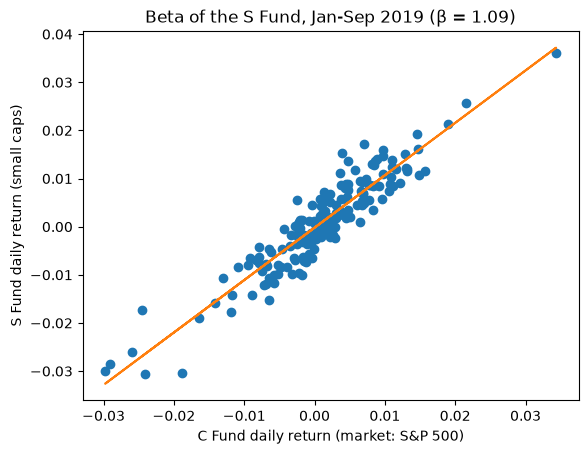

0.8689976066395095


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

data = pd.read_csv("../../data/tsp_data.csv", sep='\t', index_col=0, parse_dates=True)   # tab-separated; dates -> index, read as real dates

print(data.head())

returns = data.pct_change().dropna()   # daily returns; first row is NaN (no previous day) -> dropped

print(returns)

line_fitter = LinearRegression()
line_fitter.fit(returns[['C Fund']], returns['S Fund'])   # X: [[ ]] -> one-column DataFrame (2D); y: [ ] -> Series (1D)
predict = line_fitter.predict(returns[['C Fund']])

print(line_fitter.coef_[0], line_fitter.intercept_)   # beta, alpha (daily)

plt.figure()
plt.plot(returns[['C Fund']], returns['S Fund'], 'o')
plt.plot(returns[['C Fund']], predict)
plt.xlabel("C Fund daily return (market: S&P 500)")
plt.ylabel("S Fund daily return (small caps)")
plt.title(f"Beta of the S Fund, Jan-Sep 2019 (β = {line_fitter.coef_[0]:.2f})")   # f-string: {value:.2f} inserts the value rounded to 2 decimals
plt.savefig("charts/beta_01_s_fund.png", bbox_inches="tight")
plt.show()

# R²: share of the S Fund's variance explained by the market
print(line_fitter.score(returns[['C Fund']], returns['S Fund']))   # .score() on a regression model returns R²

**Learning points**
- `read_csv` without `sep='\t'` → the whole line lands in **one** column (the header shows `\t` everywhere). Check `data.head()` before going on.
- `.dropna` without `()` → `returns` was the **method itself** (`<bound method DataFrame.dropna ...>`), so nothing was dropped. A method only runs with `()`.
- `returns[C Fund]` → a column name is a string and needs quotes: `returns['C Fund']`.
- sklearn needs a **2D X** (rows = observations, columns = x-variables), even for one variable: `df['col']` is a Series, shape `(169,)`; `df[['col']]` is a DataFrame, shape `(169, 1)`. Check with `.shape`. The error says `Expected 2D array, got 1D array instead`. y stays 1D.
- `columns[2:]` was a leftover from the broken read: after the fix, it silently dropped two funds. When a fix changes the data's shape, recheck the code that follows.
- Plot labels copied from the soup exercise → always update labels, title and filename when reusing chart code.